# From Prediction to Decision - NASA C-MAPSS

A single RUL number is not enough to plan maintenance. This notebook adds three things on top of the
Random Forest model:

1. **Prediction intervals** - how sure is the model? (`src/conformal.py`)
2. **Explanations** - which sensors drive each prediction? (SHAP)
3. **A maintenance decision** - when should we service the engine, and does it save money? (`src/maintenance.py`)

We walk through FD001. The same steps for all four subsets are run by `models/run_phase6.py`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestRegressor

from src import conformal, maintenance as mt
from src.features import CAP, prepare, rolling_features, split_engines, last_rows

## Step 0. Data and model

In [2]:
train, test, sensors = prepare("FD001")
feats = rolling_features(train, sensors)
test_feats = last_rows(rolling_features(test, sensors))
cols = [c for c in feats.columns if c not in ("unit", "cycle", "RUL")]

tr, rest = split_engines(train, val_frac=0.4)
cal, ev = split_engines(rest, val_frac=0.5)
f_tr, f_cal, f_ev = (feats[feats.unit.isin(d.unit)] for d in (tr, cal, ev))
print("engines - train:", tr.unit.nunique(), " calibration:", cal.unit.nunique(), " evaluation:", ev.unit.nunique())

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf.fit(f_tr[cols], f_tr.RUL)

engines - train: 60  calibration: 20  evaluation: 20


RandomForestRegressor(min_samples_leaf=2, n_estimators=200, n_jobs=-1,
                      random_state=42)

The training engines are split three ways:
- **train (60%)** - fit the Random Forest
- **calibration (20%)** - engines the model has never seen, used only to measure its errors
- **evaluation (20%)** - run from cycle 1 to failure to test the maintenance policies

## Part 1. Prediction intervals (conformal prediction)

**Idea:** check how wrong the model is on the calibration engines. If 90% of its errors are smaller than *q* cycles,
then for a new engine the true RUL should be inside `[prediction - q, prediction + q]` about 90% of the time.

We compute *q* separately for three ranges of predicted RUL (below 50, 50-100, above 100), because the model is
more accurate close to failure.

In [3]:
q = conformal.fit(rf.predict(f_cal[cols]), f_cal.RUL.to_numpy(), alpha=0.1)
print("half-width q for predicted RUL <50, 50-100, >100:", q.round(1))

half-width q for predicted RUL <50, 50-100, >100: [11.8 33.1 22.8]


In [4]:
pred = rf.predict(test_feats[cols])
lower, upper = conformal.interval(pred, q)
y = np.minimum(test_feats.RUL.to_numpy(), CAP)

print("test coverage:", round(conformal.coverage(y, lower, upper), 2), "(target 0.90)")
print("mean width:   ", round(np.mean(upper - lower), 1), "cycles")

test coverage: 0.9 (target 0.90)
mean width:    43.2 cycles


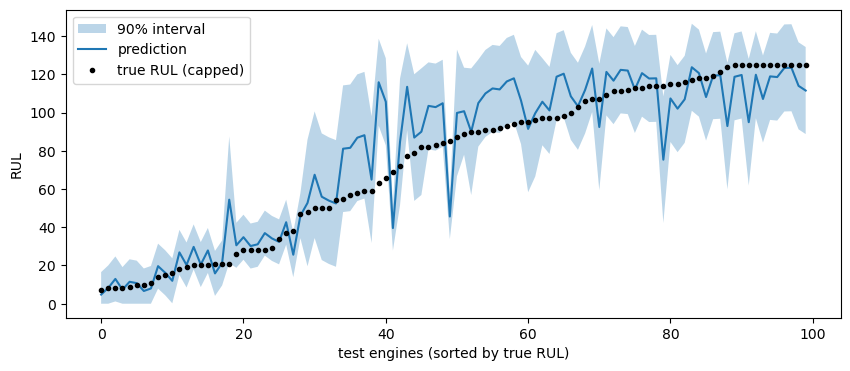

In [5]:
order = np.argsort(y)
plt.figure(figsize=(10, 4))
plt.fill_between(range(len(y)), lower[order], upper[order], alpha=0.3, label="90% interval")
plt.plot(pred[order], label="prediction")
plt.plot(y[order], "k.", label="true RUL (capped)")
plt.xlabel("test engines (sorted by true RUL)")
plt.ylabel("RUL")
plt.legend()
plt.show()

The coverage on the test engines is close to 90%, so the intervals are honest: they are not too narrow
(overconfident) or much too wide. The band is narrowest for engines close to failure, which is where it matters.

## Part 2. Health states

Each prediction is turned into a simple status:
- **Critical** - the lower end of the interval is below 10 cycles: the engine might fail soon
- **Degrading** - predicted RUL below 100
- **Healthy** - otherwise

In [6]:
states = [mt.health_state(p, lo) for p, lo in zip(pred, lower)]
pd.Series(states).value_counts()

Healthy      48
Degrading    37
Critical     15
Name: count, dtype: int64

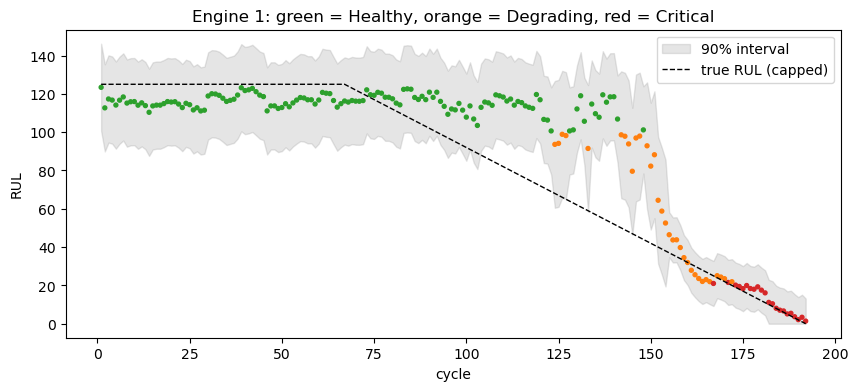

In [7]:
# one evaluation engine over its whole life
unit = ev.unit.unique()[0]
g = f_ev[f_ev.unit == unit]
p = rf.predict(g[cols])
lo, hi = conformal.interval(p, q)
colors = {"Healthy": "tab:green", "Degrading": "tab:orange", "Critical": "tab:red"}
state = [mt.health_state(a, b) for a, b in zip(p, lo)]

plt.figure(figsize=(10, 4))
plt.fill_between(g.cycle, lo, hi, alpha=0.2, color="grey", label="90% interval")
plt.scatter(g.cycle, p, c=[colors[s] for s in state], s=8)
plt.plot(g.cycle, g.RUL, "k--", lw=1, label="true RUL (capped)")
plt.xlabel("cycle")
plt.ylabel("RUL")
plt.title(f"Engine {unit}: green = Healthy, orange = Degrading, red = Critical")
plt.legend()
plt.show()

## Part 3. Explanations with SHAP

SHAP splits each prediction into contributions from every feature:
`prediction = average prediction + sum of SHAP values`. A negative SHAP value pushes the predicted RUL down
(the engine looks closer to failure).

In [8]:
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(test_feats[cols])
print("average prediction:", round(float(np.ravel(explainer.expected_value)[0]), 1))

average prediction: 85.8


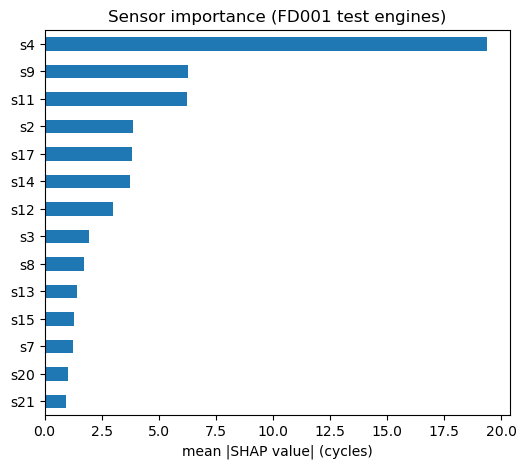

s4     19.4
s9      6.3
s11     6.3
s2      3.9
s17     3.8
dtype: float64

In [9]:
# which sensors matter most overall? (sum the 4 features of each sensor)
importance = pd.Series(np.abs(sv).mean(axis=0), index=cols)
by_sensor = importance.groupby(lambda c: c.split("_")[0]).sum().sort_values()
by_sensor.plot.barh(figsize=(6, 5))
plt.xlabel("mean |SHAP value| (cycles)")
plt.title("Sensor importance (FD001 test engines)")
plt.show()
by_sensor.sort_values(ascending=False).head(5).round(1)

s4 (LPT outlet temperature) is by far the most important sensor, followed by s9 and s11.
s4 and s11 were also among the strongest sensors in the EDA. s12 and s7 were strong in the EDA too but rank low here:
they move together with s4 and s11, so the forest mostly uses one sensor from each group and the others get little credit.
s9 (core speed) had a weak correlation in the EDA but still helps the forest, because trees can use non-linear patterns.

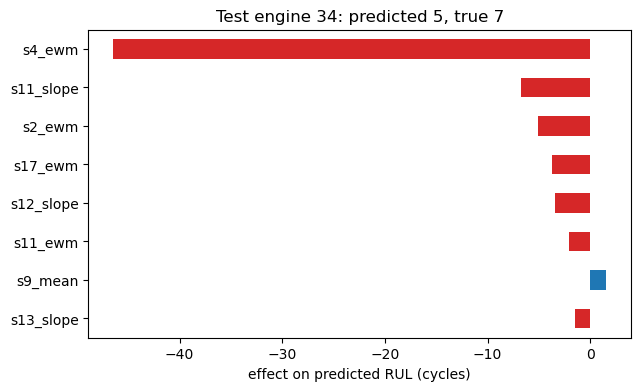

In [10]:
# why did one engine get its prediction? take the engine with the lowest predicted RUL
i = int(np.argmin(pred))
contrib = pd.Series(sv[i], index=cols)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:8])[::-1]

top.plot.barh(color=["tab:red" if v < 0 else "tab:blue" for v in top], figsize=(7, 4))
plt.xlabel("effect on predicted RUL (cycles)")
plt.title(f"Test engine {test_feats.unit.iloc[i]}: predicted {pred[i]:.0f}, true {y[i]:.0f}")
plt.show()

## Part 4. The maintenance decision

Three ways to decide when to service an engine:
- **Reactive** - run it until it fails (cost 10 per engine)
- **Fixed interval** - service every *T* cycles; *T* is chosen to be as good as possible on the training engines
- **Predictive (ours)** - service as soon as the lower end of the 90% interval drops below 10 cycles

Planned maintenance costs 1, a failure costs 10. We compare **cost per 1000 cycles flown**, so servicing too early
is also penalized: the engine flies fewer cycles for the same cost.

In [11]:
ev_pred = rf.predict(f_ev[cols])
f_ev = f_ev.assign(lower=conformal.interval(ev_pred, q)[0])
lives = f_ev.groupby("unit").cycle.max().tolist()
lowers = [g.lower.to_numpy() for _, g in f_ev.groupby("unit")]

T = mt.best_interval(tr.groupby("unit").cycle.max().tolist())
policies = {
    "Reactive": mt.reactive(lives),
    f"Fixed (every {T} cycles)": mt.fixed_interval(lives, T),
    "Predictive (ours)": mt.predictive(lives, lowers),
}
pd.DataFrame({
    name: {"cost per 1000 cycles": round(mt.cost_rate(res), 2),
           "failures": sum(c == mt.C_FAIL for c, _ in res),
           "avg cycles flown": round(np.mean([n for _, n in res]))}
    for name, res in policies.items()
}).T

,cost per 1000 cycles,failures,avg cycles flown
Reactive,46.09,20.0,217.0
Fixed (every 127 cycles),7.87,0.0,127.0
Predictive (ours),5.13,0.0,195.0


The fixed schedule avoids failures only by servicing every engine early, even long-lived ones.
The predictive policy services each engine based on its own condition, so engines fly longer and failures are still avoided.

**Why T = 127?** The shortest-lived training engine failed after 128 cycles, so the best fixed schedule services
every engine just before that. It is safe, but most engines could have flown much longer.

**How cautious should the predictive policy be?** We service when the lower bound drops below a safety margin
(10 cycles by default). A smaller margin lets engines fly longer but risks failures; a larger one is safer but wastes life.

In [12]:
rows = []
for lead in [0, 5, 10, 20, 40]:
    res = mt.predictive(lives, lowers, lead=lead)
    rows.append({"safety margin (cycles)": lead,
                 "failures": sum(c == mt.C_FAIL for c, _ in res),
                 "avg cycles flown": round(np.mean([n for _, n in res])),
                 "cost per 1000 cycles": round(mt.cost_rate(res), 2)})
pd.DataFrame(rows)

,safety margin (cycles),failures,avg cycles flown,cost per 1000 cycles
0,0,20,217,46.09
1,5,0,201,4.99
2,10,0,195,5.13
3,20,0,170,5.88
4,40,0,146,6.86


A margin of 0 never triggers (the lower bound can't go below 0), so it behaves like running to failure.
Any margin of 5 or more avoids all failures here; 5-10 cycles gives the lowest cost, and larger margins waste engine life.

## All four subsets

Computed by `models/run_phase6.py` and saved in `reports/phase6_results.csv`.

In [13]:
res = pd.read_csv("../reports/phase6_results.csv")
res[["subset", "RMSE", "coverage", "width", "fixed_T",
     "reactive_cost", "fixed_cost", "predictive_cost",
     "fixed_failures", "predictive_failures", "saving_vs_fixed_%"]].round(2)

,subset,RMSE,coverage,width,fixed_T,reactive_cost,fixed_cost,predictive_cost,fixed_failures,predictive_failures,saving_vs_fixed_%
0,FD001,15.71,0.90,43.23,127,46.09,7.87,5.13,0,0,34.89
1,FD002,14.23,0.94,52.28,128,50.59,9.16,5.67,1,0,38.12
2,FD003,15.72,0.89,44.49,144,42.89,6.94,4.62,0,0,33.41
3,FD004,16.00,0.93,53.18,127,40.00,7.87,4.55,0,0,42.24


## Conclusions

**Prediction intervals**
- Test coverage is 89-94% on all four subsets for a 90% target, so the intervals can be trusted.
- They are fairly wide (about 43-53 cycles on average). Most of the width is for healthy engines; near failure they are much narrower.

**Explanations**
- SHAP shows which sensors drive each prediction. s4 (LPT outlet temperature) dominates, followed by s9 and s11.
  Correlated sensors (s12, s7) get little credit because the forest uses one sensor from each correlated group.

**Maintenance decision**
- Predictive maintenance had **0 failures** on every subset and cost **33-42% less than the best fixed schedule**
  (fixed schedule: 1 failure on FD002). Running engines to failure is 8-10x more expensive than either.
- The saving comes from servicing each engine based on its own condition: long-lived engines are not serviced too early.

**Limitations**
- The Random Forest here is trained on 60% of the engines (the rest are needed for calibration and evaluation),
  so its RMSE (14-16) is a bit worse than in the baseline notebook (14-15).
- The evaluation set is small for FD001/FD003 (20 engines), so the exact savings percentage would change with a different split.
- Costs (1 for maintenance, 10 for a failure) are assumptions; the cost-ratio table shows how the saving changes with them.